In [ ]:
!pip install mne -q

import os, glob, warnings
import numpy as np
import mne
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from scipy.signal import stft as scipy_stft
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')
torch.manual_seed(0); np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

In [7]:
FS = 250
MI_EVENT_CODES = {'769': 0, '770': 1, '771': 2, '772': 3}
CH_NAMES_2A = ['Fz',
               'FC3', 'FC1', 'FCz', 'FC2', 'FC4',
               'C5',  'C3',  'C1',  'Cz',  'C2',  'C4',  'C6',
               'CP3', 'CP1', 'CPz', 'CP2', 'CP4',
               'P1',  'Pz',  'P2',  'POz']
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Feet', 'Tongue']

In [ ]:
# Load
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/EEG_motor/Data/2a_gdf/'

files = sorted(glob.glob(DATA_DIR + '*.gdf'))
print(f'Found {len(files)} GDF file(s).')

all_X, all_y = [], []
for f in files:
    sid = os.path.splitext(os.path.basename(f))[0]
    X, y, ch_names = load_subject(f)
    if X is None:
        print(f'  {sid}: no MI events, skipping.')
        continue
    all_X.append(X)
    all_y.append(y)
    print(f'  {sid}: X={X.shape}')

X_all = np.concatenate(all_X, axis=0)
y_all = np.concatenate(all_y, axis=0)

print(f'\nRaw EEG shape: {X_all.shape}')
unique, counts = np.unique(y_all, return_counts=True)
for label, count in zip(unique, counts):
    print(f'  Label {label} ({CLASS_NAMES[label]}): {count} samples')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 18 GDF file(s).
  A01E: no MI events, skipping.
  A01T: X=(288, 22, 751)
  A02E: no MI events, skipping.
  A02T: X=(288, 22, 751)
  A03E: no MI events, skipping.
  A03T: X=(288, 22, 751)
  A04E: no MI events, skipping.
  A04T: X=(288, 22, 751)
  A05E: no MI events, skipping.
  A05T: X=(288, 22, 751)
  A06E: no MI events, skipping.
  A06T: X=(288, 22, 751)
  A07E: no MI events, skipping.
  A07T: X=(288, 22, 751)
  A08E: no MI events, skipping.
  A08T: X=(288, 22, 751)
  A09E: no MI events, skipping.
  A09T: X=(288, 22, 751)

Raw EEG shape: (2592, 22, 751)
  Label 0 (Left Hand): 648 samples
  Label 1 (Right Hand): 648 samples
  Label 2 (Feet): 648 samples
  Label 3 (Tongue): 648 samples


In [23]:
import os
checkpoint_path = '/content/drive/MyDrive/EEG_motor/best_eeg_cnn.pt'
if os.path.exists(checkpoint_path):
    os.remove(checkpoint_path)
    print('Old checkpoint deleted.')

Old checkpoint deleted.


In [ ]:
# Preprocessing
def load_subject(file_path, tmin=0.0, tmax=3.0, l_freq=8., h_freq=30.):
    raw = mne.io.read_raw_gdf(file_path, preload=True, verbose=False)
    eog_chs = [c for c in raw.ch_names if 'EOG' in c.upper()]
    if eog_chs:
        raw.set_channel_types({c: 'eog' for c in eog_chs})
    raw.pick('eeg')
    if len(raw.ch_names) == len(CH_NAMES_2A):
        raw.rename_channels(dict(zip(raw.ch_names, CH_NAMES_2A)))
        raw.set_montage('standard_1020', match_case=False, on_missing='ignore')
    raw.filter(l_freq, h_freq, fir_design='firwin', verbose=False)
    events, event_id = mne.events_from_annotations(raw, verbose=False)
    mi_event_id = {c: event_id[c] for c in MI_EVENT_CODES if c in event_id}
    if not mi_event_id:
        return None, None, raw.ch_names
    epochs = mne.Epochs(raw, events, event_id=mi_event_id,
                        tmin=tmin, tmax=tmax,
                        baseline=None, preload=True,
                        reject_by_annotation=False, verbose=False)
    X = epochs.get_data()
    code_to_class = {event_id[c]: MI_EVENT_CODES[c] for c in mi_event_id}
    y = np.array([code_to_class[c] for c in epochs.events[:, 2]])
    return X.astype(np.float64), y.astype(np.int64), raw.ch_names

# Two class - right hand and left hand
mask = np.isin(y_all, [0, 1])
X_all_2class = X_all[mask].astype(np.float32)
y_all_2class = y_all[mask].astype(np.int64)

CLASS_NAMES_2 = ['Left Hand', 'Right Hand']

print(f'2-class dataset: {X_all_2class.shape}')
unique, counts = np.unique(y_all_2class, return_counts=True)
for label, count in zip(unique, counts):
    print(f'  Label {label} ({CLASS_NAMES_2[label]}): {count} samples')

2-class dataset: (1296, 22, 751)
  Label 0 (Left Hand): 648 samples
  Label 1 (Right Hand): 648 samples


In [ ]:
# STFT
def compute_stft(X, fs=250, win_sec=0.5, overlap=0.5):
    nperseg  = int(fs * win_sec)
    noverlap = int(nperseg * overlap)
    f, t, Z  = scipy_stft(X, fs=fs, nperseg=nperseg, noverlap=noverlap, axis=-1)
    S = np.log(np.abs(Z) + 1e-8).astype(np.float32)
    return S, f, t

X_stft_2, freqs, times = compute_stft(X_all_2class)
print(f'STFT shape: {X_stft_2.shape}')

STFT shape: (1296, 22, 63, 13)


In [ ]:
# Split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_stft_2, y_all_2class, test_size=0.2, random_state=42, stratify=y_all_2class
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

mu = X_train.mean(axis=(0, 2, 3), keepdims=True)
sd = X_train.std(axis=(0, 2, 3), keepdims=True) + 1e-6
X_train = (X_train - mu) / sd
X_val   = (X_val   - mu) / sd
X_test  = (X_test  - mu) / sd

print(f'Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}')

def to_tensor(X, y):
    return TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

BATCH_SIZE = 32
train_loader = DataLoader(to_tensor(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(to_tensor(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(to_tensor(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

Train: 777 | Val: 259 | Test: 260


In [ ]:
# Model
class EEG_CNN(nn.Module):
    def __init__(self, n_channels, n_freqs, n_times, n_classes=4, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1 — double conv
            nn.Conv2d(n_channels, 64, kernel_size=3, padding=1),  # 64 not 32
            nn.BatchNorm2d(64), nn.ELU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),           # second conv
            nn.BatchNorm2d(64), nn.ELU(),
            nn.MaxPool2d(2), nn.Dropout2d(dropout),

            # Block 2 — double conv
            nn.Conv2d(64, 128, kernel_size=3, padding=1),          # 128 not 64
            nn.BatchNorm2d(128), nn.ELU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),         # second conv
            nn.BatchNorm2d(128), nn.ELU(),
            nn.AdaptiveAvgPool2d((4, 4)), nn.Dropout2d(dropout),   # (4,4) not (4,2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ELU(),  # 128*16=2048 not 64*8=512
            nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ELU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = EEG_CNN(
    n_channels=X_stft_2.shape[1],
    n_freqs=X_stft_2.shape[2],
    n_times=X_stft_2.shape[3],
    n_classes=2,
    dropout=0.5              
).to(device)

optimizer = optim.Adam(model.parameters(), lr=5e-4, weight_decay=5e-4)  
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=8, factor=0.5)
criterion = nn.CrossEntropyLoss()  
NUM_EPOCHS = 200
EARLY_STOP_PATIENCE = 40

In [28]:
class_counts = np.bincount(y_train)
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum()
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f'Class weights: {class_weights}')


Class weights: tensor([0.5006, 0.4994], device='cuda:0')


In [29]:
train_losses, val_losses = [], []
train_accs,   val_accs   = [], []
best_val_loss = float('inf')
patience_counter = 0

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        X_batch = X_batch + 0.05 * torch.randn_like(X_batch)  # noise augmentation
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_loss += loss.item()
        correct += (outputs.argmax(1) == y_batch).sum().item()
        total   += y_batch.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            val_loss_sum += criterion(outputs, y_batch).item()
            val_correct  += (outputs.argmax(1) == y_batch).sum().item()
            val_total    += y_batch.size(0)

    val_loss = val_loss_sum / len(val_loader)
    val_acc  = val_correct / val_total
    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), '/content/drive/MyDrive/EEG_motor/best_eeg_cnn.pt')
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

    train_losses.append(train_loss); val_losses.append(val_loss)
    train_accs.append(train_acc);    val_accs.append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1:03d}/{NUM_EPOCHS}]  '
              f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.3f}  |  '
              f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.3f}')

print(f'\nTraining complete. Ran {len(train_losses)} epochs.')

Epoch [010/200]  Train Loss: 0.7229  Acc: 0.480  |  Val Loss: 0.6987  Acc: 0.502
Epoch [020/200]  Train Loss: 0.7047  Acc: 0.462  |  Val Loss: 0.6928  Acc: 0.498
Epoch [030/200]  Train Loss: 0.6985  Acc: 0.495  |  Val Loss: 0.6948  Acc: 0.502
Epoch [040/200]  Train Loss: 0.6916  Acc: 0.538  |  Val Loss: 0.6927  Acc: 0.568
Epoch [050/200]  Train Loss: 0.6922  Acc: 0.519  |  Val Loss: 0.6915  Acc: 0.556
Epoch [060/200]  Train Loss: 0.6955  Acc: 0.503  |  Val Loss: 0.6847  Acc: 0.517
Epoch [070/200]  Train Loss: 0.6613  Acc: 0.611  |  Val Loss: 0.6851  Acc: 0.548
Epoch [080/200]  Train Loss: 0.6436  Acc: 0.609  |  Val Loss: 0.7291  Acc: 0.502
Epoch [090/200]  Train Loss: 0.6221  Acc: 0.619  |  Val Loss: 0.6546  Acc: 0.598
Epoch [100/200]  Train Loss: 0.6259  Acc: 0.658  |  Val Loss: 0.6246  Acc: 0.653
Epoch [110/200]  Train Loss: 0.6228  Acc: 0.645  |  Val Loss: 0.6083  Acc: 0.618
Epoch [120/200]  Train Loss: 0.6084  Acc: 0.671  |  Val Loss: 0.6031  Acc: 0.645
Epoch [130/200]  Train Loss:

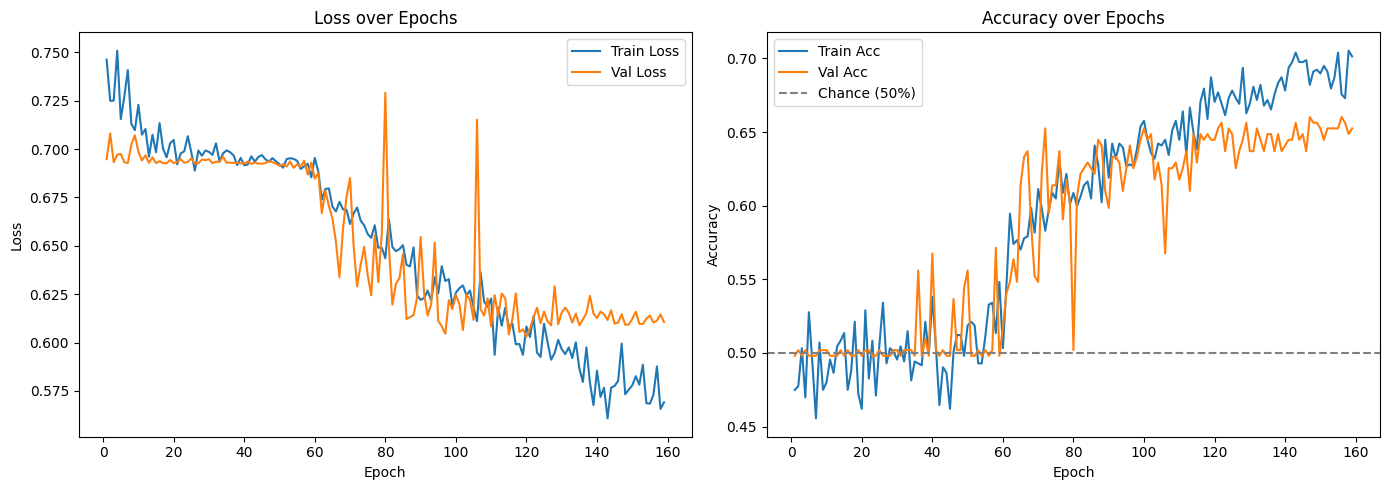

In [30]:
epochs_ran = len(train_losses)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, epochs_ran+1), train_losses, label='Train Loss')
axes[0].plot(range(1, epochs_ran+1), val_losses,   label='Val Loss')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(range(1, epochs_ran+1), train_accs, label='Train Acc')
axes[1].plot(range(1, epochs_ran+1), val_accs,   label='Val Acc')
axes[1].axhline(0.5, color='gray', linestyle='--', label='Chance (50%)')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves_2class.png', dpi=150)
plt.show()

              precision    recall  f1-score   support

   Left Hand       0.63      0.63      0.63       130
  Right Hand       0.63      0.63      0.63       130

    accuracy                           0.63       260
   macro avg       0.63      0.63      0.63       260
weighted avg       0.63      0.63      0.63       260



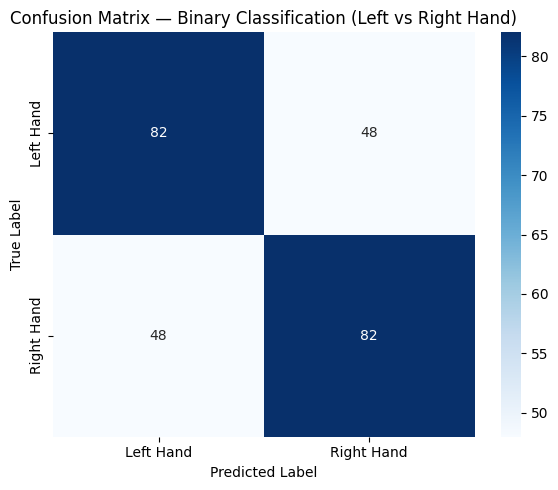

In [ ]:
# Evaluate
model.load_state_dict(torch.load('/content/drive/MyDrive/EEG_motor/best_eeg_cnn.pt', map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        preds = model(X_batch.to(device)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES_2))  # CLASS_NAMES_2 not CLASS_NAMES

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2)
plt.title('Confusion Matrix — Binary Classification (Left vs Right Hand)')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout(); plt.savefig('confusion_matrix_2class.png', dpi=150); plt.show()